# Aula 04 — Análise de Vendas em R

**Aluno:** Davi Horácio de Souza · **Matrícula:** 20250059934

Neste exercício refaço a análise da Aula 03 em **R com tidyverse**, usando o mesmo Online Retail do projeto de vendas da [`Unidade_01`](..), e respondo três perguntas de negócio novas: os produtos líderes por trimestre no Reino Unido, a concentração de receita entre os clientes e a sazonalidade por dia da semana. No final completo o "Para casa" e comparo os critérios com os da Aula 03.

Este notebook usa o **kernel R** (IRkernel). Cada resultado é seguido de uma análise.

## Configurando o ambiente R

Os pacotes foram instalados uma vez pelo terminal, a partir dos binários da Posit Package Manager para Ubuntu (assim não é preciso compilar nada):

```bash
Rscript -e 'install.packages(c("tidyverse", "readxl", "IRkernel"), repos = "https://packagemanager.posit.co/cran/__linux__/resolute/latest")'
Rscript -e 'IRkernel::installspec(name = "ir", displayname = "R")'
```

O `lubridate`, que o roteiro instala à parte, já vem dentro do tidyverse.

In [1]:
library(readxl)
library(tidyverse)

options(
  jupyter.plot_mimetypes = "image/png",
  jupyter.display_mimetypes = c("text/html", "text/plain"),
  repr.plot.width = 10,
  repr.plot.height = 4.5
)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.4     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


**Análise:** o `library(tidyverse)` carrega de uma vez os pacotes principais: `dplyr` para manipular tabelas, `ggplot2` para gráficos, `lubridate` para datas, `stringr` para texto, entre outros. A mensagem de "Conflicts" avisa que o `filter()` do dplyr passa a esconder o `filter()` do pacote `stats`, o que é esperado e não atrapalha a análise. As opções da última linha definem o formato e o tamanho dos gráficos e das tabelas no notebook.

In [2]:
pacotes <- c("readxl", "tidyverse", "dplyr", "ggplot2", "lubridate")
cat(R.version.string, "\n")
tibble(pacote = pacotes, versao = map_chr(pacotes, \(p) as.character(packageVersion(p))))

R version 4.5.2 (2025-10-31) 


pacote,versao
<chr>,<chr>
readxl,1.6.0
tidyverse,2.0.0
dplyr,1.2.1
ggplot2,4.0.4
lubridate,1.9.5


**Análise:** registrar as versões é o equivalente, em R, ao `requirements.txt` do Python: o notebook roda com R 4.5.2, tidyverse 2.0.0, dplyr 1.2.1 e ggplot2 4.0.4. Se algum resultado mudar no futuro, dá para saber se foi por causa de uma atualização de pacote.

## 1. Retomando o projeto

In [3]:
list.files("..", recursive = FALSE)

[1] "Aula_01"          "Aula_02"          "Aula_03"          "Aula_04"         
[5] "data"             "README.md"        "requirements.txt" "src"

**Análise:** a pasta da unidade continua com a mesma estrutura do projeto de vendas: as aulas, a pasta `data/` com o Online Retail, o `README.md`, o `requirements.txt` e a pasta `src/`. A análise em R lê **o mesmo arquivo** usado em Python, o que permite comparar os resultados diretamente.

## 2. O enunciado

O briefing é o mesmo da Aula 03: o gerente de vendas quer saber **quais produtos, clientes, países e períodos priorizar** e **o que prejudica o resultado**. A diferença é a ferramenta: em vez de pandas, a análise é feita com o tidyverse. Se os critérios forem os mesmos, os números precisam bater com os da Aula 03, o que serve como teste de reprodutibilidade.

## 3. Preparando os dados

In [4]:
caminho_dados <- file.path("..", "data", "online_retail.xlsx")

retail <- read_excel(caminho_dados) |>
  rename(
    invoice_no = InvoiceNo,
    stock_code = StockCode,
    description = Description,
    quantity = Quantity,
    invoice_date = InvoiceDate,
    unit_price = UnitPrice,
    customer_id = CustomerID,
    country = Country
  ) |>
  mutate(
    revenue = quantity * unit_price,
    is_cancelled = str_starts(str_to_upper(invoice_no), "C")
  )

colunas_originais <- c("invoice_no", "stock_code", "description", "quantity",
                       "invoice_date", "unit_price", "customer_id", "country")

cat("Dimensão da base:", nrow(retail), "linhas x", ncol(retail), "colunas\n")

Dimensão da base: 541909 linhas x 10 colunas


**Análise:** a base carregou com **541.909 linhas e 10 colunas**, as 8 originais mais `revenue` e `is_cancelled`, exatamente como na Aula 03. O `read_excel` já trouxe a data como data-hora, então o `as.POSIXct` do roteiro não é necessário. Para marcar os cancelamentos, usei `str_starts(str_to_upper(invoice_no), "C")`: o `str_to_upper` garante que um eventual `c` minúsculo também seria reconhecido.

## 4. Visão geral da base

In [5]:
glimpse(retail)

Rows: 541,909
Columns: 10
$ invoice_no   <chr> "536365", "536365", "536365", "536365", "536365", "536365…
$ stock_code   <chr> "85123A", "71053", "84406B", "84029G", "84029E", "22752",…
$ description  <chr> "WHITE HANGING HEART T-LIGHT HOLDER", "WHITE METAL LANTER…
$ quantity     <dbl> 6, 6, 8, 6, 6, 2, 6, 6, 6, 32, 6, 6, 8, 6, 6, 3, 2, 3, 3,…
$ invoice_date <dttm> 2010-12-01 08:26:00, 2010-12-01 08:26:00, 2010-12-01 08:…
$ unit_price   <dbl> 2.55, 3.39, 2.75, 3.39, 3.39, 7.65, 4.25, 1.85, 1.85, 1.6…
$ customer_id  <dbl> 17850, 17850, 17850, 17850, 17850, 17850, 17850, 17850, 1…
$ country      <chr> "United Kingdom", "United Kingdom", "United Kingdom", "Un…
$ revenue      <dbl> 15.30, 20.34, 22.00, 20.34, 20.34, 15.30, 25.50, 11.10, 1…
$ is_cancelled <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, F…


**Análise:** o `glimpse()` é o equivalente do `info()` do pandas: mostra cada coluna com o tipo e os primeiros valores. O `read_excel` adivinhou os tipos sozinho: `invoice_no` e `stock_code` vieram como texto (`<chr>`), porque há códigos com letras logo nas primeiras linhas, e `customer_id` veio como número decimal (`<dbl>`), já que o readxl lê todo número do Excel como `double`. A diferença em relação ao Python é que em R o cliente ausente aparece como `NA` sem precisar converter o tipo.

In [6]:
retail |>
  summarise(
    inicio = min(invoice_date),
    fim = max(invoice_date),
    notas = n_distinct(invoice_no),
    clientes = n_distinct(customer_id, na.rm = TRUE),
    produtos = n_distinct(stock_code),
    paises = n_distinct(country)
  )

inicio,fim,notas,clientes,produtos,paises
<dttm>,<dttm>,<int>,<int>,<int>,<int>
2010-12-01 08:26:00,2011-12-09 12:50:00,25900,4372,4070,38


**Análise:** os números da visão geral são **idênticos aos da Aula 03**: 25.900 notas, 4.372 clientes, 4.070 produtos, 38 países e o mesmo período (01/12/2010 a 09/12/2011). É o primeiro sinal de que a leitura em R e em Python chegou ao mesmo dado.

In [7]:
retail |> select(quantity, unit_price, revenue) |> summary()

    quantity            unit_price            revenue          
 Min.   :-80995.000   Min.   :-11062.060   Min.   :-168469.60  
 1st Qu.:     1.000   1st Qu.:     1.250   1st Qu.:      3.40  
 Median :     3.000   Median :     2.080   Median :      9.75  
 Mean   :     9.552   Mean   :     4.611   Mean   :     17.99  
 3rd Qu.:    10.000   3rd Qu.:     4.130   3rd Qu.:     17.40  
 Max.   : 80995.000   Max.   : 38970.000   Max.   : 168469.60  

**Análise:** o `summary()` mostra os mesmos extremos vistos em Python: quantidade de **−80.995 a +80.995**, preço mínimo de **−£ 11.062,06** e faturamento por linha de **±£ 168.469,60**. A mediana (3 unidades, £ 2,08, £ 9,75) continua muito longe dos máximos, o que confirma a presença de valores extremos.

## 5. Qualidade dos dados

In [8]:
tibble(
  coluna = colunas_originais,
  ausentes = map_int(retail[colunas_originais], \(coluna) sum(is.na(coluna))),
  percentual = round(map_dbl(retail[colunas_originais], \(coluna) mean(is.na(coluna)) * 100), 2)
) |>
  arrange(desc(ausentes))

coluna,ausentes,percentual
<chr>,<int>,<dbl>
customer_id,135080,24.93
description,1454,0.27
invoice_no,0,0.00
stock_code,0,0.00
quantity,0,0.00
invoice_date,0,0.00
unit_price,0,0.00
country,0,0.00


**Análise:** a tabela de ausentes foi montada com `map_int` e `map_dbl` do pacote `purrr`, que aplicam a mesma função a cada coluna. O resultado bate com o da Aula 03: **24,93% das linhas sem cliente** e 0,27% sem descrição.

In [9]:
duplicadas <- retail |> select(all_of(colunas_originais)) |> duplicated()
cat("Linhas duplicadas:", scales::comma(sum(duplicadas)), "(", scales::percent(mean(duplicadas), accuracy = 0.01), ")\n")

Linhas duplicadas: 5,268 ( 0.97% )


**Análise:** as mesmas **5.268 linhas duplicadas (0,97%)**. O `duplicated()` do R base funciona sobre as 8 colunas originais selecionadas com `all_of()`.

In [10]:
tibble(
  metrica = c("Faturas canceladas", "Quantidade negativa", "Quantidade igual a zero", "Preço negativo",
              "Preço igual a zero", "Descrição ausente", "Cliente não identificado", "Data inválida ou ausente"),
  linhas = c(
    sum(retail$is_cancelled), sum(retail$quantity < 0), sum(retail$quantity == 0), sum(retail$unit_price < 0),
    sum(retail$unit_price == 0), sum(is.na(retail$description)), sum(is.na(retail$customer_id)), sum(is.na(retail$invoice_date))
  )
)

metrica,linhas
<chr>,<int>
Faturas canceladas,9288
Quantidade negativa,10624
Quantidade igual a zero,0
Preço negativo,2
Preço igual a zero,2515
Descrição ausente,1454
Cliente não identificado,135080
Data inválida ou ausente,0


**Análise:** a contagem dos registros suspeitos é a mesma da Aula 03, linha por linha: 9.288 linhas de notas canceladas, 10.624 com quantidade negativa, 2 com preço negativo, 2.515 com preço zero e 135.080 sem cliente.

In [11]:
percentis <- c(0.01, 0.25, 0.5, 0.75, 0.99)
tibble(
  percentil = scales::percent(percentis),
  quantity = quantile(retail$quantity, percentis),
  unit_price = quantile(retail$unit_price, percentis)
)

percentil,quantity,unit_price
<chr>,<dbl>,<dbl>
1%,-2,0.19
25%,1,1.25
50%,3,2.08
75%,10,4.13
99%,100,18.00


**Análise:** os percentis também coincidem: **98% das linhas têm quantidade entre −2 e 100** e 99% têm preço até £ 18. Em R, o `quantile()` com um vetor de probabilidades calcula todos os percentis de uma vez.

## 6. Isolando as vendas válidas

In [12]:
vendas <- retail |> filter(!is_cancelled, quantity > 0, unit_price > 0)

vendas |>
  summarise(
    linhas = n(),
    pedidos = n_distinct(invoice_no),
    clientes = n_distinct(customer_id, na.rm = TRUE),
    unidades = sum(quantity),
    faturamento_bruto = round(sum(revenue), 2)
  )

linhas,pedidos,clientes,unidades,faturamento_bruto
<int>,<int>,<int>,<dbl>,<dbl>
530104,19960,4338,5588376,10666685


**Análise:** o mesmo filtro (`!is_cancelled, quantity > 0, unit_price > 0`) chega aos mesmos **530.104 linhas, 19.960 pedidos, 4.338 clientes e 5.588.376 unidades**. O faturamento bruto aparece como 10666685 porque o tibble arredonda a exibição para os dígitos significativos, mas o valor é o mesmo **£ 10.666.684,54** da Aula 03.

## 7. Indicadores de pedidos, produtos, países e clientes

### 7.1 Valor médio dos pedidos

In [13]:
pedidos <- vendas |>
  group_by(invoice_no) |>
  summarise(
    order_date = min(invoice_date),
    customer_id = first(customer_id),
    country = first(country),
    item_quantity = sum(quantity),
    order_value = sum(revenue),
    .groups = "drop"
  )

pedidos |> summarise(ticket_medio = round(mean(order_value), 2), ticket_mediano = round(median(order_value), 2))

ticket_medio,ticket_mediano
<dbl>,<dbl>
534.4,303.84


**Análise:** ticket médio de **£ 534,40** e mediano de **£ 303,84**, os mesmos do Python. Em R, agrupar por nota fiscal com `group_by()` + `summarise()` faz o papel do `groupby().agg()` do pandas.

In [14]:
pedidos |> reframe(percentil = c(25, 50, 75, 90, 99), valor_pedido = round(quantile(order_value, percentil / 100), 2))

percentil,valor_pedido
<dbl>,<dbl>
25,152.51
50,303.84
75,495.62
90,940.89
99,4821.17


**Análise:** o `reframe()` permite que um resumo devolva várias linhas (um valor por percentil), coisa que o `summarise()` não faz. Os percentis batem com os da Aula 03: 75% dos pedidos abaixo de £ 495,62 e 99% abaixo de £ 4.821,17.

### 7.2 Produtos com maior faturamento, volume e frequência

In [15]:
produtos <- vendas |>
  filter(!is.na(description)) |>
  group_by(stock_code, description) |>
  summarise(units_sold = sum(quantity), revenue = sum(revenue), order_count = n_distinct(invoice_no), .groups = "drop")

produtos |> slice_max(revenue, n = 10, with_ties = FALSE)

stock_code,description,units_sold,revenue,order_count
<chr>,<chr>,<dbl>,<dbl>,<int>
DOT,DOTCOM POSTAGE,706,206248.77,706
22423,REGENCY CAKESTAND 3 TIER,13879,174484.74,1988
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
47566,PARTY BUNTING,18295,99504.33,1685
85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
M,Manual,7224,78110.27,289
POST,POSTAGE,3150,78101.88,1126


**Análise:** o ranking por faturamento repete os problemas vistos na Aula 03: o **frete (`DOTCOM POSTAGE`) em 1º lugar**, o `PAPER CRAFT` em 3º com um único pedido (estornado) e os lançamentos `Manual` e `POSTAGE` no top 10. O `slice_max(..., with_ties = FALSE)` garante exatamente 10 linhas mesmo em caso de empate.

In [16]:
produtos |> slice_max(units_sold, n = 10, with_ties = FALSE)

stock_code,description,units_sold,revenue,order_count
<chr>,<chr>,<dbl>,<dbl>,<int>
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047,13841.85,535
85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
22197,POPCORN HOLDER,36761,34298.87,803
84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1455
21212,PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10,1320
23084,RABBIT NIGHT LIGHT,30788,66964.99,994


**Análise:** por volume, os dois primeiros lugares continuam sendo os pedidos gigantes isolados (PAPER CRAFT e STORAGE JAR), e o `WORLD WAR 2 GLIDERS` aparece com 55 mil unidades e só £ 13,8 mil de faturamento. A ferramenta mudou, mas a distorção é a mesma, porque está nos dados.

In [17]:
produtos |> slice_max(order_count, n = 10, with_ties = FALSE)

stock_code,description,units_sold,revenue,order_count
<chr>,<chr>,<dbl>,<dbl>,<int>
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
22423,REGENCY CAKESTAND 3 TIER,13879,174484.74,1988
47566,PARTY BUNTING,18295,99504.33,1685
20725,LUNCH BAG RED RETROSPOT,19353,35752.01,1564
84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1455
22720,SET OF 3 CAKE TINS PANTRY DESIGN,7493,38158.39,1385
21212,PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10,1320
20727,LUNCH BAG BLACK SKULL.,12240,22421.21,1273


**Análise:** o ranking por frequência é, de novo, o mais robusto: `WHITE HANGING HEART T-LIGHT HOLDER` (2.189 pedidos), `JUMBO BAG RED RETROSPOT` (2.089) e `REGENCY CAKESTAND 3 TIER` (1.988) lideram. São os produtos comprados de forma recorrente pelo maior número de pedidos.

### 7.3 Países mais relevantes para o negócio

In [18]:
paises <- vendas |>
  group_by(country) |>
  summarise(
    revenue = sum(revenue),
    order_count = n_distinct(invoice_no),
    customer_count = n_distinct(customer_id, na.rm = TRUE),
    units_sold = sum(quantity),
    .groups = "drop"
  ) |>
  mutate(share = round(revenue / sum(revenue) * 100, 2))

paises |> slice_max(revenue, n = 10, with_ties = FALSE)

country,revenue,order_count,customer_count,units_sold,share
<chr>,<dbl>,<int>,<int>,<dbl>,<dbl>
United Kingdom,9025222.08,18019,3920,4662390,84.61
Netherlands,285446.34,94,9,200361,2.68
EIRE,283453.96,288,3,147173,2.66
Germany,228867.14,457,94,119261,2.15
France,209715.11,392,87,112103,1.97
Australia,138521.31,57,9,83901,1.30
Spain,61577.11,90,30,27940,0.58
Switzerland,57089.90,54,21,30629,0.54
Belgium,41196.34,98,25,23237,0.39


**Análise:** o Reino Unido responde por **84,61%** do faturamento, seguido de Holanda, Irlanda, Alemanha e França, com os mesmos valores da Aula 03. Continua visível o contraste entre mercados concentrados (Holanda com 9 clientes, Irlanda com 3) e mercados diversificados (Alemanha com 94 clientes, França com 87).

### 7.4 Clientes mais relevantes para o negócio

In [19]:
clientes <- vendas |>
  filter(!is.na(customer_id)) |>
  group_by(customer_id) |>
  summarise(
    revenue = sum(revenue),
    order_count = n_distinct(invoice_no),
    units_sold = sum(quantity),
    country = first(country),
    .groups = "drop"
  )

clientes |> slice_max(revenue, n = 10, with_ties = FALSE)

customer_id,revenue,order_count,units_sold,country
<dbl>,<dbl>,<int>,<dbl>,<chr>
14646,280206.02,73,196915,Netherlands
18102,259657.30,60,64124,United Kingdom
17450,194550.79,46,69993,United Kingdom
16446,168472.50,2,80997,United Kingdom
14911,143825.06,201,80265,EIRE
12415,124914.53,21,77374,Australia
14156,117379.63,55,57885,EIRE
17511,91062.38,31,64549,United Kingdom
16029,81024.84,63,40208,United Kingdom


**Análise:** o top 10 de clientes é o mesmo, incluindo as duas distorções já identificadas: o **16446** (£ 168 mil em 2 pedidos) e o **12346** (£ 77 mil em 1 pedido), que só aparecem por causa dos pedidos gigantes estornados.

## 8. Cancelamentos e devoluções

In [20]:
retail |>
  summarise(
    faturas_canceladas = n_distinct(invoice_no[is_cancelled]),
    linhas_quantidade_negativa = sum(quantity < 0),
    valor_devolucoes_ajustes = round(abs(sum(revenue[revenue < 0])), 2),
    receita_liquida = round(sum(revenue), 2)
  )

faturas_canceladas,linhas_quantidade_negativa,valor_devolucoes_ajustes,receita_liquida
<int>,<int>,<dbl>,<dbl>
3836,10624,918936.6,9747748


**Análise:** mesmos números da Aula 03: **3.836 notas canceladas**, 10.624 linhas com quantidade negativa, **£ 918.936,61** em devoluções e ajustes e uma receita líquida de **£ 9,75 milhões** na base inteira.

## 9. Indo além: novas perguntas de negócio

### 9.1 Produtos mais vendidos por trimestre, no Reino Unido

In [21]:
vendas |>
  filter(country == "United Kingdom") |>
  mutate(trimestre = paste0(year(invoice_date), "-T", quarter(invoice_date))) |>
  group_by(trimestre, stock_code, description) |>
  summarise(units_sold = sum(quantity), revenue = round(sum(revenue), 2), .groups = "drop") |>
  slice_max(units_sold, n = 5, by = trimestre, with_ties = FALSE) |>
  arrange(trimestre, desc(units_sold))

trimestre,stock_code,description,units_sold,revenue
<chr>,<chr>,<chr>,<dbl>,<dbl>
2010-T4,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4571,993.17
2010-T4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,3633,10109.91
2010-T4,22834,HAND WARMER BABUSHKA DESIGN,3322,4481.88
2010-T4,21212,PACK OF 72 RETROSPOT CAKE CASES,3266,2266.38
2010-T4,22693,GROW A FLYTRAP OR SUNFLOWER IN TIN,2617,2509.01
2011-T1,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,77183.60
2011-T1,85099B,JUMBO BAG RED RETROSPOT,10224,19241.42
2011-T1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,8874,24541.12
2011-T1,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,8609,2067.31


**Análise:** o top 5 de cada trimestre no Reino Unido mostra três coisas. **Primeiro, distorção:** o 1º lugar do 1º trimestre (STORAGE JAR, 74.215) e o do 4º trimestre de 2011 (PAPER CRAFT, 80.995) são os pedidos gigantes estornados, ou seja, não são campeões de verdade. **Segundo, sazonalidade de produto:** o aquecedor de mãos (`HAND WARMER`) aparece em dezembro, o leque (`SILK FAN`) no 2º trimestre e o `PAPER CHAIN KIT 50'S CHRISTMAS` e a `RABBIT NIGHT LIGHT` no 4º. **Terceiro, campeões perenes:** o `WORLD WAR 2 GLIDERS` está no top 5 dos cinco trimestres, o `WHITE HANGING HEART` em quatro, e o `JUMBO BAG RED RETROSPOT` e o `POPCORN HOLDER` em três. Um detalhe de qualidade: o código 22197 aparece como `SMALL POPCORN HOLDER` no 2º trimestre e como `POPCORN HOLDER` nos outros, porque a descrição mudou ao longo do ano. Agrupar pela descrição pode dividir um mesmo produto em dois. O 4º trimestre de 2010 tem só dezembro.

### 9.2 Concentração de receita: quantos clientes sustentam o faturamento?

In [22]:
receita_clientes <- clientes |>
  select(customer_id, revenue) |>
  arrange(desc(revenue)) |>
  mutate(
    posicao = row_number(),
    pct_clientes = posicao / n(),
    participacao_acumulada = cumsum(revenue) / sum(revenue)
  )

clientes_80 <- receita_clientes |> filter(participacao_acumulada >= 0.8) |> slice_head(n = 1) |> pull(posicao)
total_clientes <- nrow(receita_clientes)

cat(clientes_80, "de", total_clientes, "clientes (", scales::percent(clientes_80 / total_clientes, accuracy = 0.1),
    ") respondem por 80% do faturamento das vendas válidas.\n")

1133 de 4338 clientes ( 26.1% ) respondem por 80% do faturamento das vendas válidas.


**Análise:** **1.133 dos 4.338 clientes (26,1%) respondem por 80% do faturamento**. É uma concentração próxima da "regra 80/20": cerca de um quarto da base sustenta quatro quintos da receita. Para o negócio, isso define onde o esforço de retenção tem mais retorno.

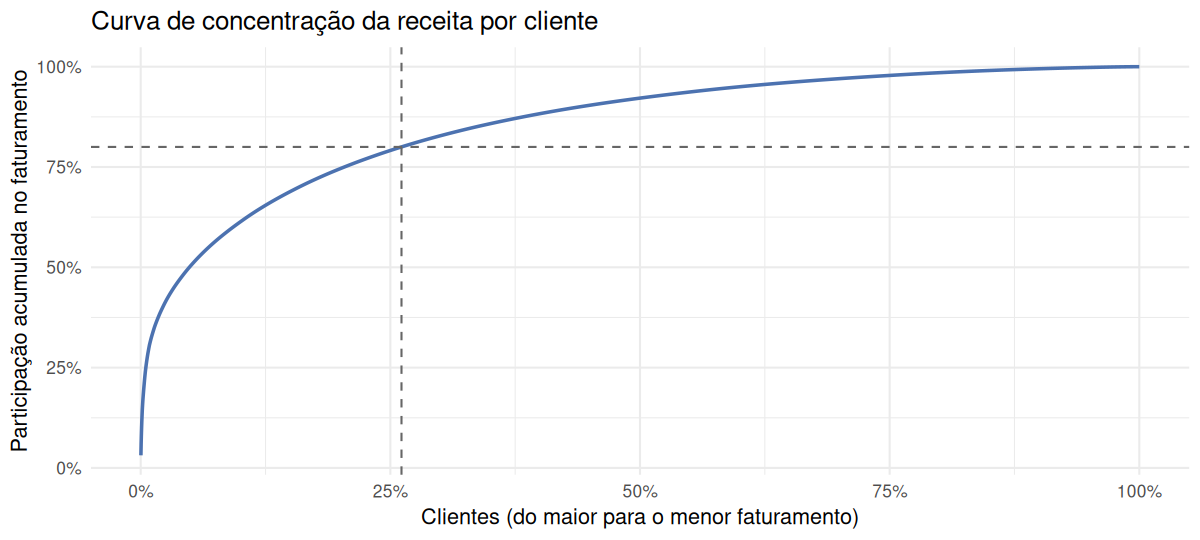

In [23]:
ggplot(receita_clientes, aes(x = pct_clientes, y = participacao_acumulada)) +
  geom_line(color = "#4C72B0", linewidth = 1) +
  geom_hline(yintercept = 0.8, linetype = "dashed", color = "grey40") +
  geom_vline(xintercept = clientes_80 / total_clientes, linetype = "dashed", color = "grey40") +
  scale_x_continuous(labels = scales::percent) +
  scale_y_continuous(labels = scales::percent) +
  labs(
    title = "Curva de concentração da receita por cliente",
    x = "Clientes (do maior para o menor faturamento)",
    y = "Participação acumulada no faturamento"
  ) +
  theme_minimal(base_size = 13)

**Análise:** a curva sobe muito rápido no começo: os primeiros 5% de clientes já respondem por cerca de metade do faturamento, e a curva cruza 80% na linha tracejada vertical (26,1% dos clientes). Depois disso ela fica quase plana, ou seja, os três quartos restantes de clientes, somados, trazem só 20% da receita.

### 9.3 Sazonalidade por dia da semana

In [24]:
vendas |>
  mutate(dia_semana = wday(invoice_date, label = TRUE, abbr = FALSE, week_start = 1)) |>
  group_by(dia_semana) |>
  summarise(pedidos = n_distinct(invoice_no), faturamento = round(sum(revenue), 2), .groups = "drop") |>
  mutate(ticket_medio = round(faturamento / pedidos, 2), participacao = scales::percent(faturamento / sum(faturamento), accuracy = 0.1))

dia_semana,pedidos,faturamento,ticket_medio,participacao
<ord>,<int>,<dbl>,<dbl>,<chr>
segunda,3126,1779575.0,569.28,16.7%
terça,3554,2178632.6,613.01,20.4%
quarta,3690,1851147.8,501.67,17.4%
quinta,4246,2203161.2,518.88,20.7%
sexta,3140,1840340.2,586.10,17.3%
domingo,2204,813827.6,369.25,7.6%


**Análise:** **não há nenhum pedido aos sábados**: a loja não processa vendas nesse dia. Entre os dias com vendas, **quinta (20,7%) e terça (20,4%)** são os mais fortes e somam 41% do faturamento. A quinta tem mais pedidos (4.246), e a terça tem o maior ticket médio (£ 613). O **domingo** é o dia mais fraco: só 7,6% do faturamento e o menor ticket (£ 369), o que sugere pedidos menores, provavelmente de clientes de varejo e não de atacadistas.

## 10. Para casa

### 10.1 Sazonalidade mensal

In [25]:
mensal <- vendas |>
  mutate(mes = floor_date(invoice_date, "month")) |>
  group_by(mes) |>
  summarise(
    faturamento = round(sum(revenue), 2),
    pedidos = n_distinct(invoice_no),
    clientes = n_distinct(customer_id, na.rm = TRUE),
    .groups = "drop"
  ) |>
  mutate(ticket_medio = round(faturamento / pedidos, 2))

mensal

mes,faturamento,pedidos,clientes,ticket_medio
<dttm>,<dbl>,<int>,<int>,<dbl>
2010-12-01,823746.1,1559,885,528.38
2011-01-01,691364.6,1086,741,636.62
2011-02-01,523631.9,1100,758,476.03
2011-03-01,717639.4,1454,974,493.56
2011-04-01,537808.6,1246,856,431.63
2011-05-01,770536.0,1681,1056,458.38
2011-06-01,761739.9,1533,991,496.89
2011-07-01,719221.2,1475,949,487.61
2011-08-01,759138.4,1361,935,557.78


**Análise:** a tabela mensal reproduz a da Aula 03: estabilidade entre £ 520 mil e £ 770 mil no primeiro semestre e alta a partir de setembro, até **£ 1,51 mi em novembro**, quase 3 vezes fevereiro. O número de clientes acompanha (1.664 em novembro contra 758 em fevereiro), então o crescimento vem de mais clientes comprando, e não de pedidos maiores.

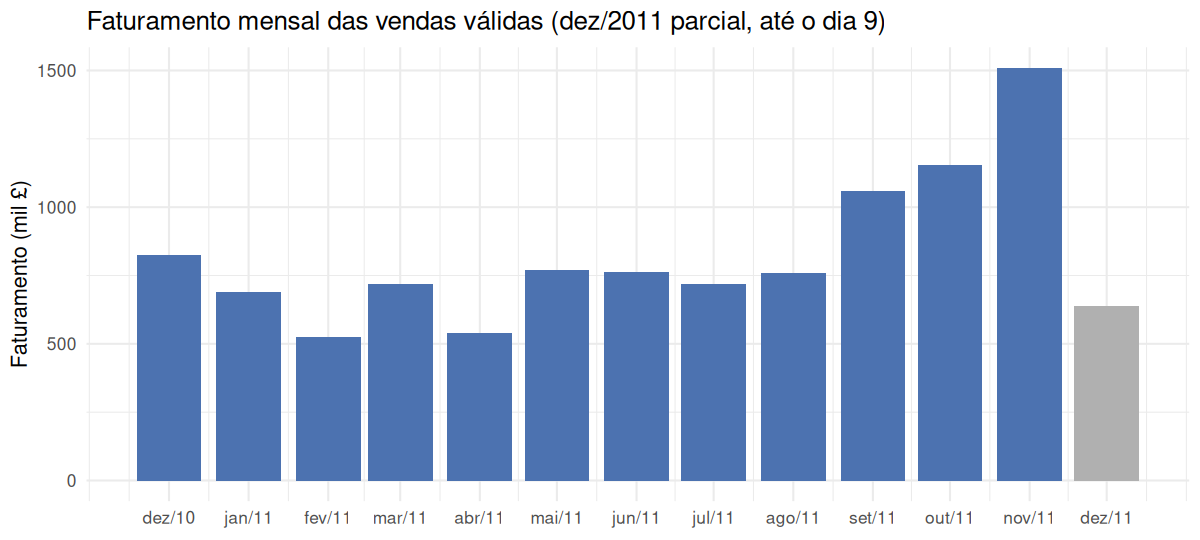

In [26]:
mensal |>
  mutate(parcial = mes == max(mes)) |>
  ggplot(aes(x = mes, y = faturamento / 1000, fill = parcial)) +
  geom_col() +
  scale_fill_manual(values = c(`FALSE` = "#4C72B0", `TRUE` = "#B0B0B0"), guide = "none") +
  scale_x_datetime(date_labels = "%b/%y", breaks = mensal$mes) +
  labs(title = "Faturamento mensal das vendas válidas (dez/2011 parcial, até o dia 9)", x = NULL, y = "Faturamento (mil £)") +
  theme_minimal(base_size = 13)

**Análise:** o gráfico em `ggplot2` mostra a mesma sazonalidade do gráfico feito com matplotlib na Aula 03: setembro, outubro e novembro concentram cerca de 35% do faturamento do ano. A barra cinza de dezembro de 2011 não é uma queda: o mês só vai até o dia 9.

### 10.2 Investigando os outliers

In [27]:
retail |>
  filter(abs(quantity) >= 10000) |>
  select(invoice_no, stock_code, description, quantity, unit_price, revenue, customer_id, invoice_date) |>
  arrange(invoice_date)

invoice_no,stock_code,description,quantity,unit_price,revenue,customer_id,invoice_date
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346,2011-01-18 10:01:00
C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.6,12346,2011-01-18 10:17:00
578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,0.0,13256,2011-11-25 15:57:00
581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446,2011-12-09 09:15:00
C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.6,16446,2011-12-09 09:27:00


**Análise:** as linhas com mais de 10 mil unidades são as mesmas investigadas na Aula 03: dois pedidos gigantes (74.215 e 80.995 unidades) **estornados pelo mesmo cliente 16 e 12 minutos depois**, e uma linha de 12.540 adesivos com preço zero. Nenhuma delas é uma venda real.

In [28]:
retail |>
  filter(!str_detect(stock_code, "\\d")) |>
  group_by(stock_code) |>
  summarise(descricao = first(description), linhas = n(), valor = round(sum(revenue), 2), .groups = "drop") |>
  arrange(desc(linhas))

stock_code,descricao,linhas,valor
<chr>,<chr>,<int>,<dbl>
POST,POSTAGE,1256,66230.64
DOT,DOTCOM POSTAGE,710,206245.48
M,Manual,571,-68674.19
D,Discount,77,-5696.22
S,SAMPLES,63,-3049.39
BANK CHARGES,Bank Charges,37,-7175.64
AMAZONFEE,AMAZON FEE,34,-221520.50
CRUK,CRUK Commission,16,-7933.43
DCGSSGIRL,GIRLS PARTY BAG,13,144.43


**Análise:** os códigos sem dígito são os mesmos: frete (`POST`, `DOT`), lançamentos manuais, descontos, amostras, tarifas, taxas da Amazon (−£ 221 mil), comissões e ajuste de dívida. `DCGSSGIRL`, `DCGSSBOY` e `PADS` continuam sendo exceções, porque são produtos reais. Em R, o `str_detect(stock_code, "\\d")` faz o mesmo papel do `str.contains(r"\d")` do pandas.

### 10.3 Critérios: mudaram em relação à Aula 03?

**Não mudaram.** Revendo o diagnóstico em R, os mesmos problemas aparecem, então mantenho os critérios da Aula 03:

- **Venda válida:** nota sem `C`, quantidade e preço positivos, código de produto e sem as duas linhas estornadas minutos depois.
- **Cancelamento/devolução:** nota com prefixo `C`. O dataset não permite separar uma da outra.
- **Ajuste de estoque:** quantidade negativa sem nota `C`, sempre com preço zero e sem cliente.
- **Registro anômalo:** códigos que não são produto (frete, taxas, manual, descontos, amostras, ajuste de dívida) e os pedidos gigantes estornados.

O que muda é só a implementação: em R, a base limpa usa `filter(!stock_code %in% ...)` e um `anti_join()` para retirar as linhas estornadas. Se os critérios forem realmente os mesmos, o resultado precisa ser idêntico ao do Python, e a tabela abaixo testa isso.

In [29]:
codigos_nao_produto <- c("POST", "DOT", "C2", "M", "m", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "B")

cancelamentos_gigantes <- retail |>
  filter(is_cancelled, quantity <= -10000) |>
  transmute(customer_id, stock_code, quantity = -quantity)

vendas_limpas <- vendas |>
  filter(!stock_code %in% codigos_nao_produto) |>
  anti_join(cancelamentos_gigantes, by = c("customer_id", "stock_code", "quantity"))

resumo <- function(dados, nome) {
  pedidos_base <- dados |> group_by(invoice_no) |> summarise(valor = sum(revenue), .groups = "drop")
  tibble(
    base = nome,
    linhas = nrow(dados),
    pedidos = nrow(pedidos_base),
    faturamento = round(sum(dados$revenue), 2),
    ticket_medio = round(mean(pedidos_base$valor), 2),
    ticket_mediano = round(median(pedidos_base$valor), 2)
  )
}

bind_rows(resumo(vendas, "roteiro"), resumo(vendas_limpas, "base limpa"))

base,linhas,pedidos,faturamento,ticket_medio,ticket_mediano
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>
roteiro,530104,19960,10666685,534.40,303.84
base limpa,527790,19771,10026466,507.13,302.58


**Análise:** a base limpa em R tem **527.790 linhas, 19.771 pedidos, £ 10.026.465,67 de faturamento e ticket médio de £ 507,13**, exatamente os mesmos números da Aula 03, até os centavos. Isso mostra que a análise é **reprodutível**: critérios explícitos levam ao mesmo resultado, seja em pandas ou no tidyverse. Também se repete a diferença entre as medidas: o ticket médio cai £ 27 com a limpeza, enquanto o mediano quase não se move.

In [30]:
clientes_limpos <- vendas_limpas |>
  filter(!is.na(customer_id)) |>
  group_by(customer_id) |>
  summarise(revenue = sum(revenue), .groups = "drop") |>
  arrange(desc(revenue)) |>
  mutate(participacao_acumulada = cumsum(revenue) / sum(revenue))

clientes_80_limpo <- which(clientes_limpos$participacao_acumulada >= 0.8)[1]
cat("Base limpa:", clientes_80_limpo, "de", nrow(clientes_limpos), "clientes (",
    scales::percent(clientes_80_limpo / nrow(clientes_limpos), accuracy = 0.1), ") respondem por 80% do faturamento.\n")

Base limpa: 1166 de 4333 clientes ( 26.9% ) respondem por 80% do faturamento.


**Análise:** na base limpa, **1.166 de 4.333 clientes (26,9%)** respondem por 80% do faturamento. A concentração fica um pouco menor que no roteiro (26,1%) porque os pedidos estornados inflavam artificialmente dois clientes. Cinco clientes saem da base porque só tinham linhas removidas. A conclusão continua a mesma: pouco mais de um quarto dos clientes sustenta a receita.

## 11. Recomendações para a gerência de vendas

**1. Criar um programa de relacionamento para os ~1.170 clientes que sustentam 80% da receita.** São 27% da base de clientes identificados (base limpa). Perder parte deles tem um impacto desproporcional, então esses clientes merecem atendimento prioritário, condições comerciais diferenciadas e acompanhamento de frequência de compra, com alerta quando um cliente importante fica muito tempo sem comprar.

**2. Concentrar campanhas e lançamentos de terça a quinta.** Esses três dias somam cerca de 58% do faturamento, e terça e quinta, sozinhas, 41%. Ações comerciais nesses dias alcançam o momento em que os clientes já estão comprando. O domingo (7,6% do faturamento, ticket de £ 369) pode receber ações voltadas a pedidos menores. Também vale avaliar se abrir o processamento de pedidos aos **sábados**, hoje sem nenhuma venda, traria receita nova ou só redistribuiria a dos outros dias.

**3. Planejar o estoque por trimestre, separando produtos perenes e sazonais.** Os campeões perenes (`JUMBO BAG RED RETROSPOT`, `WHITE HANGING HEART`, `POPCORN HOLDER`, `WORLD WAR 2 GLIDERS`) aparecem no top 5 em três a cinco dos cinco trimestres e nunca podem faltar. Já os sazonais têm janela certa: itens de inverno em dezembro, o leque no 2º trimestre e os itens de Natal (`PAPER CHAIN KIT`, `RABBIT NIGHT LIGHT`) no 4º trimestre, que concentra 35% do faturamento anual.

**4. Padronizar o cadastro de produtos.** O mesmo código (22197) aparece com duas descrições ao longo do ano. Relatórios de produto devem agrupar pelo **código** (`stock_code`), e a descrição deveria ser única por código, para que um produto não apareça dividido em dois nos rankings.

## Conclusão

Refazer a análise em R mostrou que **a ferramenta muda, mas o raciocínio não**: com os mesmos critérios, o tidyverse chegou exatamente aos mesmos números do pandas, até a base limpa de £ 10.026.465,67. As perguntas novas acrescentaram três informações importantes para o negócio: a receita depende de pouco mais de um quarto dos clientes (Pareto), as vendas se concentram de terça a quinta e não existem aos sábados, e há produtos perenes e sazonais com janelas bem definidas ao longo do ano. Também apareceu um problema de qualidade novo, as descrições diferentes para o mesmo código de produto, que só ficou visível ao agrupar por trimestre.